# Практическая работа по лекции 1. EDA временного ряда, пропуски и выбросы

**Выполнил: Голубенко Никита.**

**Цель работы:** выбрать открытый временной ряд, выполнить первичный анализ (EDA), проверить качество временного индекса, исследовать пропуски и выбросы, сравнить методы импутации на искусственно скрытых значениях и сформулировать выводы.

## Источник данных

Используется открытый **Bike Sharing Dataset** (почасовое количество аренд велосипедов в системе Capital Bikeshare, Вашингтон, США, 2011–2012 гг.). Анализируется целевая переменная `cnt` — общее количество аренд за час. Временная метка формируется из полей `dteday` и `hr`.

- Официальная страница UCI: https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset
- Автор датасета: Hadi Fanaee-T; лицензия — CC BY 4.0.
- CSV-зеркало для загрузки: https://raw.githubusercontent.com/udacity/deep-learning/master/first-neural-network/Bike-Sharing-Dataset/hour.csv

**Замечание.** В исходном CSV нет пустых ячеек, но не все календарные часы представлены отдельными строками. Отсутствующая временная метка сама по себе не доказывает ошибку регистрации: в источниках по этому набору пропущенные часы трактуются как периоды без аренд. Поэтому в работе такие часы сначала отмечаются как отсутствующие наблюдения (`NaN`), а не автоматически заменяются нулями. Для сравнения импутации дополнительно искусственно скрывается часть известных значений `cnt`, метрики рассчитываются только на этих контрольных точках.

В разделе импутации сравниваются все четыре метода, перечисленные в практике лекции: `ffill`, линейная интерполяция, медиана и `seasonal naive`. 

## 1. Импорт библиотек и загрузка открытого датасета

Если `hour.csv` уже находится рядом с ноутбуком или в папке `data/`, используется локальный файл. Иначе ноутбук загружает его из открытого зеркала GitHub, а затем пробует скачать официальный архив UCI. Скачанный CSV сохраняется рядом с ноутбуком для повторного запуска без сети.

In [1]:
from pathlib import Path
from io import BytesIO
import zipfile
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

SEED = 2026
OUTPUT_DIR = Path('results_lecture1_eda')
OUTPUT_DIR.mkdir(exist_ok=True)

LOCAL_CANDIDATES = [Path('hour.csv'), Path('data/hour.csv'), Path('Bike-Sharing-Dataset/hour.csv')]
GITHUB_CSV_URL = 'https://raw.githubusercontent.com/udacity/deep-learning/master/first-neural-network/Bike-Sharing-Dataset/hour.csv'
UCI_ZIP_URL = 'https://archive.ics.uci.edu/static/public/275/bike+sharing+dataset.zip'

source_description = ''
local_path = next((p for p in LOCAL_CANDIDATES if p.exists()), None)
if local_path is not None:
    raw = pd.read_csv(local_path)
    source_description = f'локальный файл: {local_path.as_posix()}'
else:
    download_errors = []
    try:
        raw = pd.read_csv(GITHUB_CSV_URL)
        source_description = f'открытое зеркало CSV: {GITHUB_CSV_URL}'
    except Exception as exc:
        download_errors.append(f'GitHub CSV: {exc}')
        try:
            with urllib.request.urlopen(UCI_ZIP_URL, timeout=30) as response:
                zip_bytes = response.read()
            with zipfile.ZipFile(BytesIO(zip_bytes)) as archive:
                member = next(name for name in archive.namelist() if name.lower().endswith('/hour.csv') or name.lower() == 'hour.csv')
                with archive.open(member) as csv_file:
                    raw = pd.read_csv(csv_file)
            source_description = f'официальный архив UCI: {UCI_ZIP_URL}'
        except Exception as exc:
            download_errors.append(f'UCI ZIP: {exc}')
            raise RuntimeError(
                'Не удалось получить Bike Sharing Dataset через интернет. '
                'Скачайте hour.csv с официальной страницы UCI и положите его рядом с ноутбуком. '
                'Источники: https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset\n' + '\n'.join(download_errors)
            ) from exc
    # Сохраняем скачанные исходные данные для повторного запуска без сети.
    try:
        raw.to_csv('hour.csv', index=False)
    except OSError:
        pass

print('Источник данных:', source_description)
print('Размер исходной таблицы:', raw.shape)
display(raw.head())

Источник данных: локальный файл: hour.csv
Размер исходной таблицы: (17379, 17)


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


## 2. Подготовка данных и проверка временного индекса

Разбираются дата и час, записи сортируются по времени, проверяются дубликаты временных меток, пропущенные значения в исходных полях и допустимость значений целевой переменной. Затем формируется полная почасовая сетка. Восстановление пропущенных значений на этом шаге не выполняется.

In [2]:
required_columns = {'dteday', 'hr', 'cnt'}
missing_columns = required_columns.difference(raw.columns)
if missing_columns:
    raise ValueError(f'В датасете не хватает обязательных колонок: {sorted(missing_columns)}')

raw = raw.copy()
raw['timestamp'] = pd.to_datetime(raw['dteday'], errors='coerce') + pd.to_timedelta(pd.to_numeric(raw['hr'], errors='coerce'), unit='h')
raw['cnt'] = pd.to_numeric(raw['cnt'], errors='coerce')
invalid_timestamp_rows = int(raw['timestamp'].isna().sum())
source_missing_cells = int(raw.drop(columns=['timestamp'], errors='ignore').isna().sum().sum())
source_missing_cnt = int(raw['cnt'].isna().sum())
negative_cnt_rows = int((raw['cnt'] < 0).sum())

rows_before_cleaning = len(raw)
raw = raw.dropna(subset=['timestamp']).sort_values('timestamp').copy()
duplicate_timestamp_count = int(raw['timestamp'].duplicated(keep='first').sum())
raw_clean = raw.drop_duplicates(subset='timestamp', keep='first').copy()
raw_clean = raw_clean.set_index('timestamp').sort_index()

expected_index = pd.date_range(raw_clean.index.min().floor('h'), raw_clean.index.max().floor('h'), freq='h', name='timestamp')
missing_timestamp_index = expected_index.difference(raw_clean.index)
missing_timestamp_count = len(missing_timestamp_index)
extra_timestamp_count = len(raw_clean.index.difference(expected_index))

# Аналитический ряд имеет равномерный шаг в один час; отсутствующие часы остаются NaN.
series = raw_clean['cnt'].reindex(expected_index).astype(float).rename('cnt')
analysis_df = series.to_frame()

quality_check = pd.DataFrame({
    'Проверка': [
        'Строк в исходном CSV',
        'Строк с некорректной временной меткой',
        'Дубликаты временных меток',
        'Пропущенные ячейки в исходных столбцах',
        'Пропущенные значения cnt в строках исходного CSV',
        'Отрицательные значения cnt',
        'Пропущенные часовые метки после регуляризации',
        'Наблюдений на полной почасовой сетке',
    ],
    'Результат': [
        rows_before_cleaning,
        invalid_timestamp_rows,
        duplicate_timestamp_count,
        source_missing_cells,
        source_missing_cnt,
        negative_cnt_rows,
        missing_timestamp_count,
        len(series),
    ]
})
display(quality_check)
print('Период:', series.index.min(), '—', series.index.max())
print('Частота временной сетки: 1 час')

,Проверка,Результат
0,Строк в исходном CSV,17379
1,Строк с некорректной временной меткой,0
2,Дубликаты временных меток,0
3,Пропущенные ячейки в исходных столбцах,0
4,Пропущенные значения cnt в строках исходного CSV,0
5,Отрицательные значения cnt,0
6,Пропущенные часовые метки после регуляризации,165
7,Наблюдений на полной почасовой сетке,17544


Период: 2011-01-01 00:00:00 — 2012-12-31 23:00:00
Частота временной сетки: 1 час


## 3. График всего ряда и скользящие статистики

Строится график почасового количества аренд за весь период, а также скользящие среднее и стандартное отклонение на окне 24 часа. Скользящие статистики показывают краткосрочный уровень и изменчивость ряда. Пропуски не заполняются для построения исходного графика.

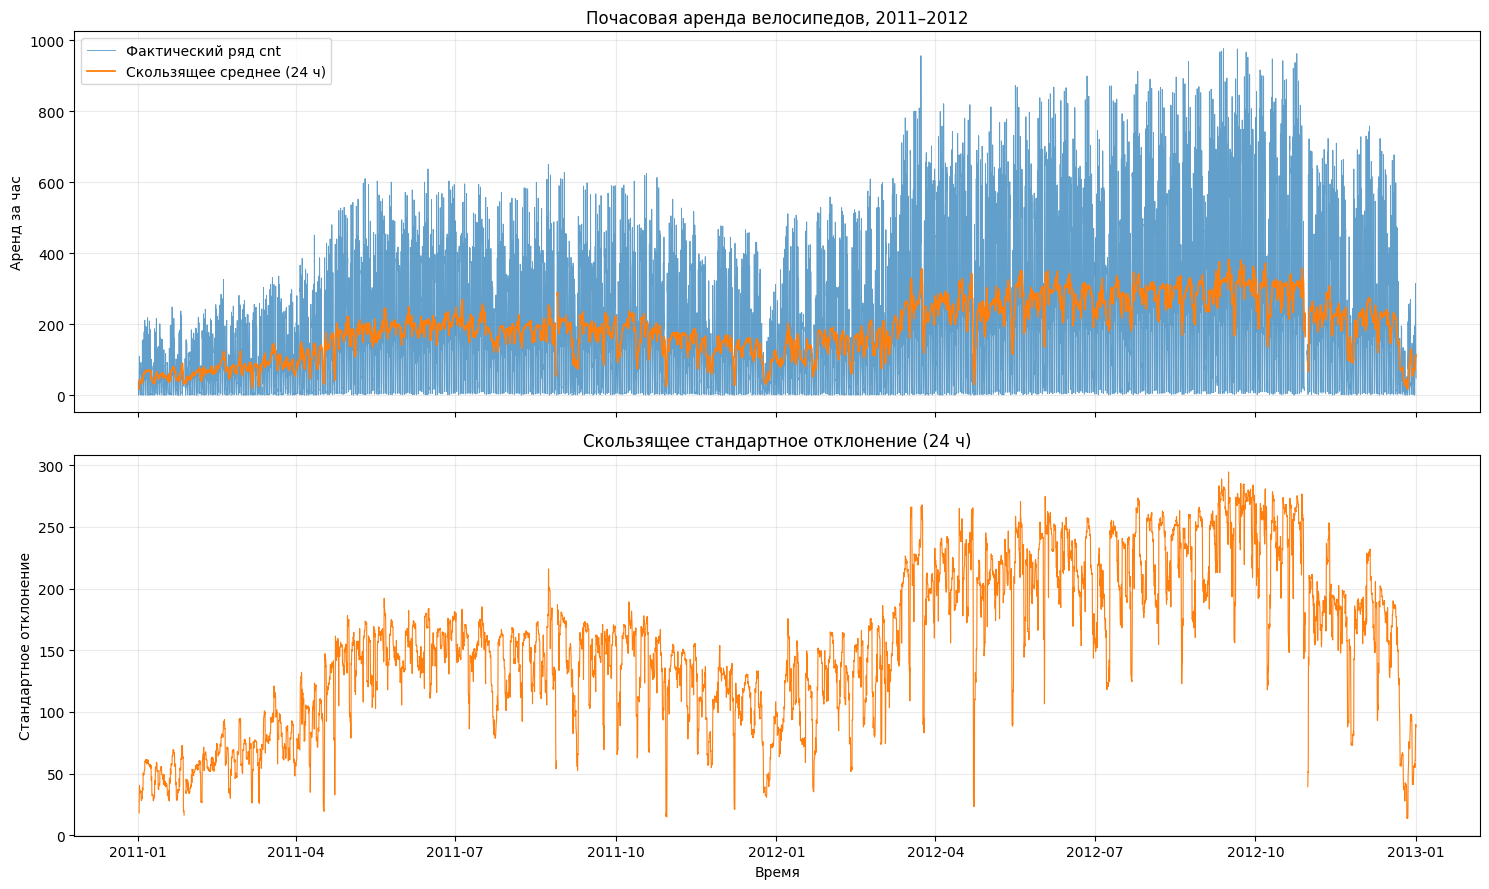

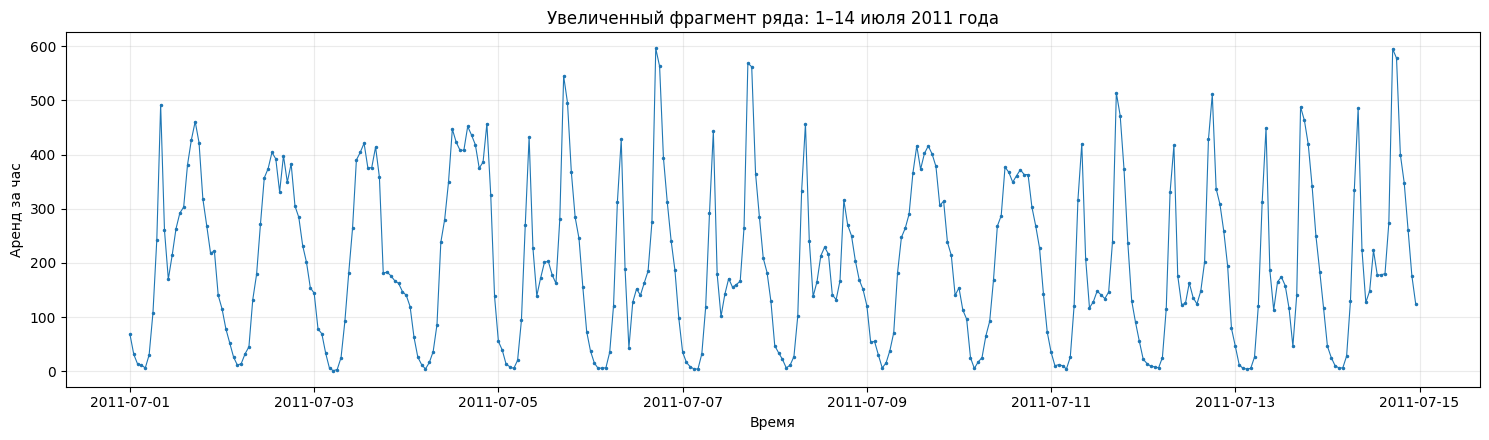

In [3]:
rolling_mean_24h = series.rolling(24, min_periods=12).mean()
rolling_std_24h = series.rolling(24, min_periods=12).std()

fig, axes = plt.subplots(2, 1, figsize=(15, 9), sharex=True)
axes[0].plot(series.index, series.values, linewidth=0.65, alpha=0.7, label='Фактический ряд cnt')
axes[0].plot(rolling_mean_24h.index, rolling_mean_24h.values, linewidth=1.3, label='Скользящее среднее (24 ч)')
axes[0].set_title('Почасовая аренда велосипедов, 2011–2012')
axes[0].set_ylabel('Аренд за час')
axes[0].legend()
axes[0].grid(True, alpha=0.25)
axes[1].plot(rolling_std_24h.index, rolling_std_24h.values, linewidth=0.8, color='tab:orange')
axes[1].set_title('Скользящее стандартное отклонение (24 ч)')
axes[1].set_ylabel('Стандартное отклонение')
axes[1].set_xlabel('Время')
axes[1].grid(True, alpha=0.25)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / '01_full_series_rolling.png', dpi=150, bbox_inches='tight')
plt.show()

# Отдельный увеличенный фрагмент: первые две недели июля 2011 года.
zoom = series.loc['2011-07-01':'2011-07-14']
fig, ax = plt.subplots(figsize=(15, 4.5))
ax.plot(zoom.index, zoom.values, marker='.', markersize=3, linewidth=0.8)
ax.set_title('Увеличенный фрагмент ряда: 1–14 июля 2011 года')
ax.set_xlabel('Время')
ax.set_ylabel('Аренд за час')
ax.grid(True, alpha=0.25)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / '02_zoom_fragment.png', dpi=150, bbox_inches='tight')
plt.show()

## 4. Сезонные подсерии и календарная тепловая карта

Для часового ряда рассматриваются среднее количество аренд по часу суток и по дню недели. Тепловая карта построена в формате «час × день недели»: в каждой ячейке показано среднее число аренд для соответствующего часа и дня недели.

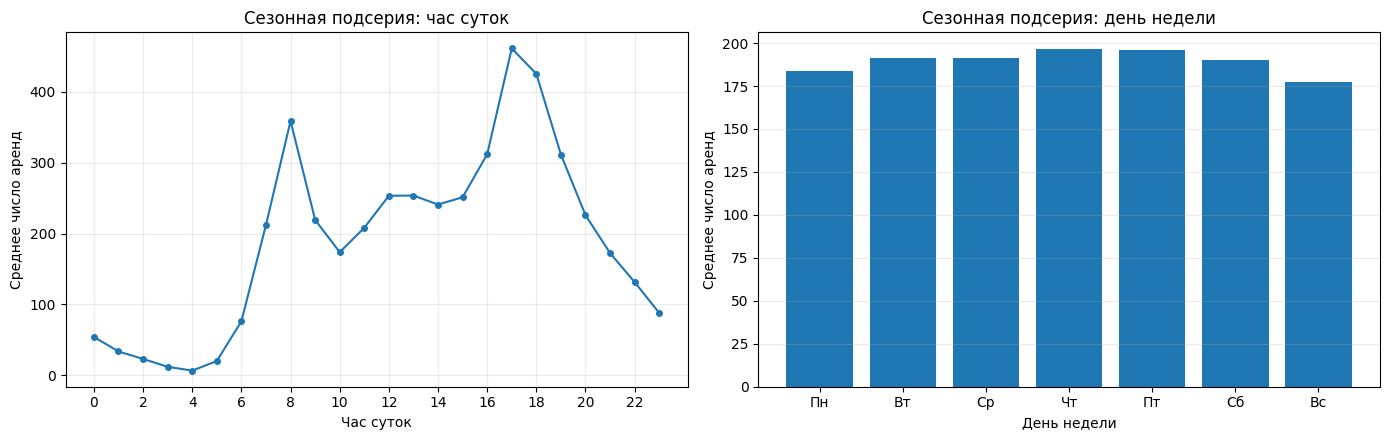

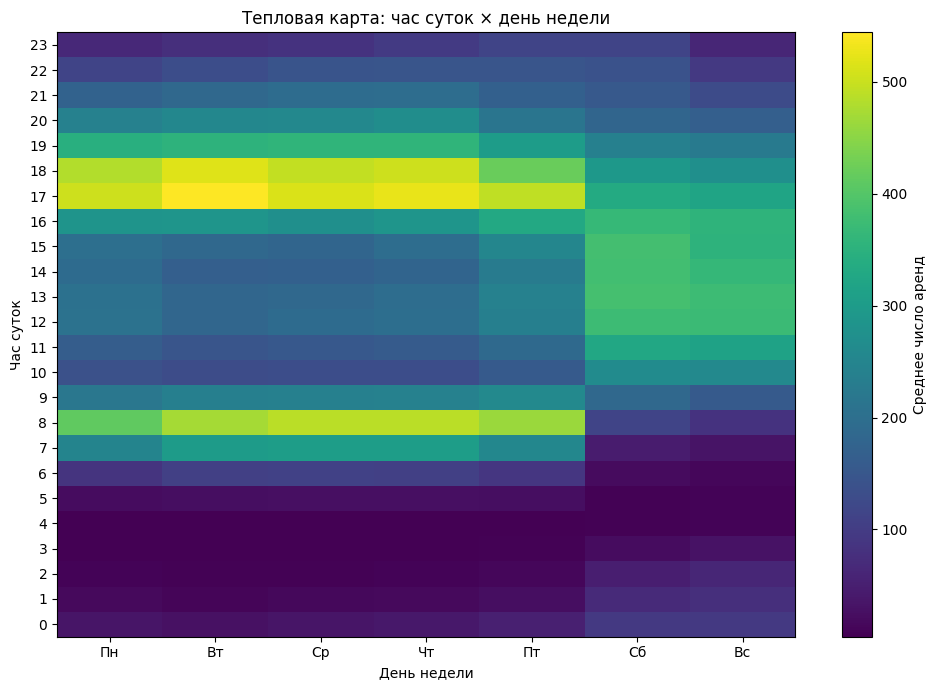

,Среднее число аренд
Час суток,
0,53.898072
1,33.375691
2,22.869930
3,11.727403
4,6.352941
5,19.889819
6,76.044138
7,212.064649
8,359.011004


,Среднее число аренд
День недели,
Пн,183.744655
Вт,191.238891
Ср,191.130505
Чт,196.436665
Пт,196.135907
Сб,190.209793
Вс,177.468825


In [4]:
observed = series.dropna()
calendar = pd.DataFrame({'cnt': observed.values}, index=observed.index)
calendar['hour_of_day'] = calendar.index.hour
calendar['weekday'] = calendar.index.dayofweek  # понедельник=0, воскресенье=6
weekday_labels = ['Пн', 'Вт', 'Ср', 'Чт', 'Пт', 'Сб', 'Вс']

hour_profile = calendar.groupby('hour_of_day')['cnt'].mean().reindex(range(24))
weekday_profile = calendar.groupby('weekday')['cnt'].mean().reindex(range(7))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(hour_profile.index, hour_profile.values, marker='o', markersize=4)
axes[0].set_title('Сезонная подсерия: час суток')
axes[0].set_xlabel('Час суток')
axes[0].set_ylabel('Среднее число аренд')
axes[0].set_xticks(range(0, 24, 2))
axes[0].grid(True, alpha=0.25)
axes[1].bar([weekday_labels[i] for i in weekday_profile.index], weekday_profile.values)
axes[1].set_title('Сезонная подсерия: день недели')
axes[1].set_xlabel('День недели')
axes[1].set_ylabel('Среднее число аренд')
axes[1].grid(axis='y', alpha=0.25)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / '03_seasonal_subseries.png', dpi=150, bbox_inches='tight')
plt.show()

heatmap = calendar.groupby(['hour_of_day', 'weekday'])['cnt'].mean().unstack('weekday').reindex(index=range(24), columns=range(7))
fig, ax = plt.subplots(figsize=(10, 7))
im = ax.imshow(heatmap.values, aspect='auto', origin='lower', interpolation='nearest')
ax.set_title('Тепловая карта: час суток × день недели')
ax.set_xlabel('День недели')
ax.set_ylabel('Час суток')
ax.set_xticks(range(7), weekday_labels)
ax.set_yticks(range(0, 24, 1))
fig.colorbar(im, ax=ax, label='Среднее число аренд')
fig.tight_layout()
fig.savefig(OUTPUT_DIR / '04_heatmap_hour_weekday.png', dpi=150, bbox_inches='tight')
plt.show()

display(pd.DataFrame({'Среднее число аренд': hour_profile}).rename_axis('Час суток'))
display(pd.DataFrame({'Среднее число аренд': weekday_profile.values}, index=weekday_labels).rename_axis('День недели'))

## 5. Анализ тренда и возможных структурных сдвигов

Для проверки изменения уровня ряда рассчитываются среднемесячные значения `cnt` и покрытие каждого месяца наблюдениями. Дополнительно сравниваются средние по каждому году и одинаковым календарным месяцам 2011 и 2012 годов. Сопоставление одинаковых месяцев частично снижает влияние сезонности.

Это описательная проверка возможного сдвига уровня, а не формальный тест точки структурного разрыва. Двух лет наблюдений недостаточно, чтобы уверенно отделить долгосрочный тренд от сезонности, календарных эффектов и изменений условий эксплуатации. Средние рассчитываются по присутствующим записям. Если пропущенные часы соответствуют нулевому спросу, а не пропускам регистрации, их исключение повышает оценку среднего.

,Среднее cnt по имеющимся записям,Число имеющихся часов,Ожидаемое число часов,"Покрытие, %"
Месяц,,,,
2011-01-01,55.51,688,744,92.47
2011-02-01,74.29,649,672,96.58
2011-03-01,87.73,730,744,98.12
2011-04-01,131.95,719,720,99.86
2011-05-01,182.56,744,744,100.00
2011-06-01,199.32,720,720,100.00
2011-07-01,189.97,744,744,100.00
2011-08-01,186.99,731,744,98.25
2011-09-01,177.71,717,720,99.58


,Среднее cnt,Медиана cnt,Число записей
Год,,,
2011,143.79,109.0,8645
2012,234.67,191.0,8734


,Среднее 2011,Среднее 2012,"Изменение 2012 к 2011, %"
Месяц,,,
1,55.51,130.56,135.21
2,74.29,149.04,100.62
3,87.73,221.90,152.93
4,131.95,242.65,83.90
5,182.56,263.26,44.21
6,199.32,281.71,41.33
7,189.97,273.67,44.05
8,186.99,288.31,54.18
9,177.71,303.57,70.83


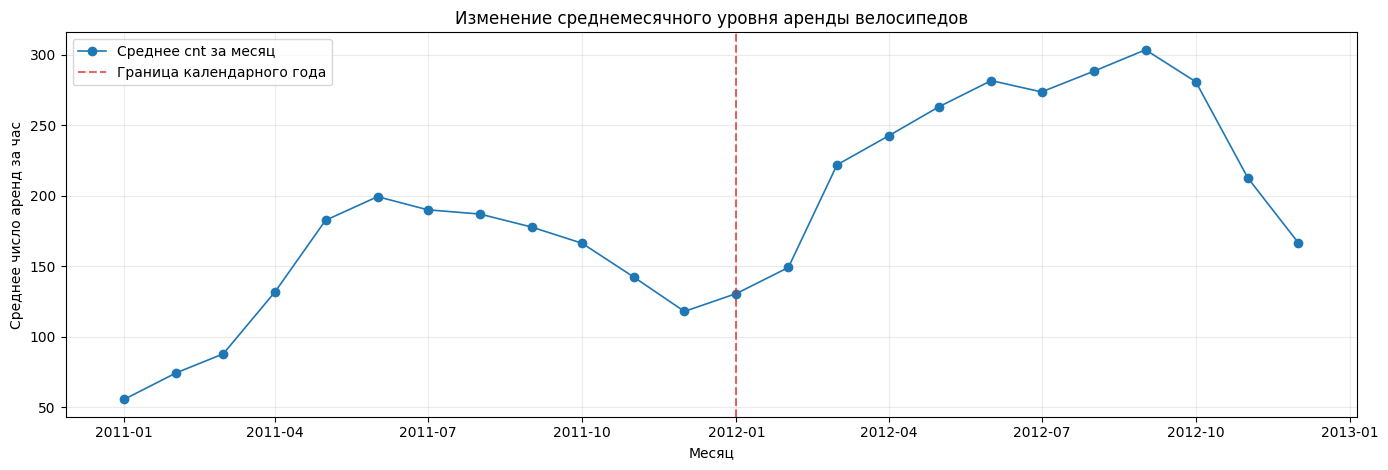

Изменение среднего уровня между 2011 и 2012 гг.: 63.20%
В 12 из 12 сопоставимых календарных месяцев среднее 2012 г. выше среднего 2011 г.
Среднее изменение по сопоставимым месяцам: 73.94%.
Эти различия указывают на возможное изменение уровня ряда.


In [5]:
# Среднее по каждому календарному месяцу и доля фактически представленных часов.
monthly_mean = series.resample('MS').mean()
monthly_count = series.resample('MS').count()
monthly_expected = pd.Series(1, index=series.index).resample('MS').count()
monthly_summary = pd.DataFrame({
    'Среднее cnt по имеющимся записям': monthly_mean,
    'Число имеющихся часов': monthly_count,
    'Ожидаемое число часов': monthly_expected,
})
monthly_summary['Покрытие, %'] = 100 * monthly_summary['Число имеющихся часов'] / monthly_summary['Ожидаемое число часов']
monthly_summary.index.name = 'Месяц'
display(monthly_summary.round(2))
monthly_summary.to_csv(OUTPUT_DIR / 'monthly_trend_and_coverage.csv')

# Годовые характеристики.
annual_summary = series.groupby(series.index.year).agg(['mean', 'median', 'count'])
annual_summary.index.name = 'Год'
annual_summary = annual_summary.rename(columns={'mean': 'Среднее cnt', 'median': 'Медиана cnt', 'count': 'Число записей'})
display(annual_summary.round(2))
annual_summary.to_csv(OUTPUT_DIR / 'annual_summary.csv')

# Сравнение одинаковых календарных месяцев двух лет.
monthly_pairs = pd.DataFrame({
    'year': series.index.year,
    'month': series.index.month,
    'cnt': series.values,
}).groupby(['month', 'year'])['cnt'].mean().unstack('year')
if 2011 in monthly_pairs.columns and 2012 in monthly_pairs.columns:
    yoy = pd.DataFrame({'Среднее 2011': monthly_pairs[2011], 'Среднее 2012': monthly_pairs[2012]})
    yoy['Изменение 2012 к 2011, %'] = 100 * (yoy['Среднее 2012'] / yoy['Среднее 2011'] - 1).replace([np.inf, -np.inf], np.nan)
    yoy.index.name = 'Месяц'
    display(yoy.round(2))
    yoy.to_csv(OUTPUT_DIR / 'year_over_year_same_month.csv')
    comparable_months = yoy['Изменение 2012 к 2011, %'].dropna()
    positive_months = int((comparable_months > 0).sum())
    mean_yoy_change_pct = float(comparable_months.mean())
else:
    yoy = pd.DataFrame()
    positive_months = 0
    mean_yoy_change_pct = float('nan')

if len(annual_summary) >= 2:
    first_year, last_year = int(annual_summary.index.min()), int(annual_summary.index.max())
    annual_mean_change_pct = 100 * (annual_summary.loc[last_year, 'Среднее cnt'] / annual_summary.loc[first_year, 'Среднее cnt'] - 1)
else:
    first_year = last_year = int(annual_summary.index[0]) if len(annual_summary) else 0
    annual_mean_change_pct = float('nan')

# График помесячного уровня; разрыв между годами показан вертикальной линией.
fig, ax = plt.subplots(figsize=(14, 4.8))
ax.plot(monthly_mean.index, monthly_mean.values, marker='o', linewidth=1.2, label='Среднее cnt за месяц')
if len(monthly_mean):
    ax.axvline(pd.Timestamp(f'{monthly_mean.index[-1].year}-01-01'), color='tab:red', linestyle='--', alpha=0.7,
               label='Граница календарного года')
ax.set_title('Изменение среднемесячного уровня аренды велосипедов')
ax.set_xlabel('Месяц')
ax.set_ylabel('Среднее число аренд за час')
ax.legend()
ax.grid(True, alpha=0.25)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / '04_trend_and_level_shift.png', dpi=150, bbox_inches='tight')
plt.show()

print(f'Изменение среднего уровня между {first_year} и {last_year} гг.: {annual_mean_change_pct:.2f}%')
if len(yoy):
    print(f'В {positive_months} из {len(comparable_months)} сопоставимых календарных месяцев среднее 2012 г. выше среднего 2011 г.')
    print(f'Среднее изменение по сопоставимым месяцам: {mean_yoy_change_pct:.2f}%.')
print('Эти различия указывают на возможное изменение уровня ряда.')

## 6. Анализ пропусков и отсутствующих временных меток

Сначала подсчитываются пропуски в значениях исходного CSV. Затем отдельно анализируются отсутствующие часы, которые возникают при приведении временного индекса к полной почасовой сетке. Для пропусков вычисляются расположение и длина непрерывных последовательностей.

Отдельно различаются пропуски `cnt` в строках исходного файла и часы, отсутствующие как строки CSV. В наборе Bike Sharing отсутствие часа может быть связано с отсутствием аренд, поэтому `NaN` на регулярной сетке не интерпретируется автоматически как ошибка датчика.

,Показатель,Значение
0,Пропуски в целевой переменной исходного CSV,0.00
1,Отсутствующие часовые метки (добавлены как NaN),165.00
2,NaN в аналитическом ряду после регуляризации,165.00
3,"Доля NaN в аналитическом ряду, %",0.94
4,Непрерывные последовательности пропусков,75.00
5,"Максимальная последовательность, часов",36.00


,Начало,Конец,Часов в последовательности
0,2011-01-02 05:00:00,2011-01-02 05:00:00,1
1,2011-01-03 02:00:00,2011-01-03 03:00:00,2
2,2011-01-04 03:00:00,2011-01-04 03:00:00,1
3,2011-01-05 03:00:00,2011-01-05 03:00:00,1
4,2011-01-06 03:00:00,2011-01-06 03:00:00,1
5,2011-01-07 03:00:00,2011-01-07 03:00:00,1
6,2011-01-11 03:00:00,2011-01-11 04:00:00,2
7,2011-01-12 03:00:00,2011-01-12 04:00:00,2
8,2011-01-14 04:00:00,2011-01-14 04:00:00,1
9,2011-01-18 00:00:00,2011-01-18 11:00:00,12


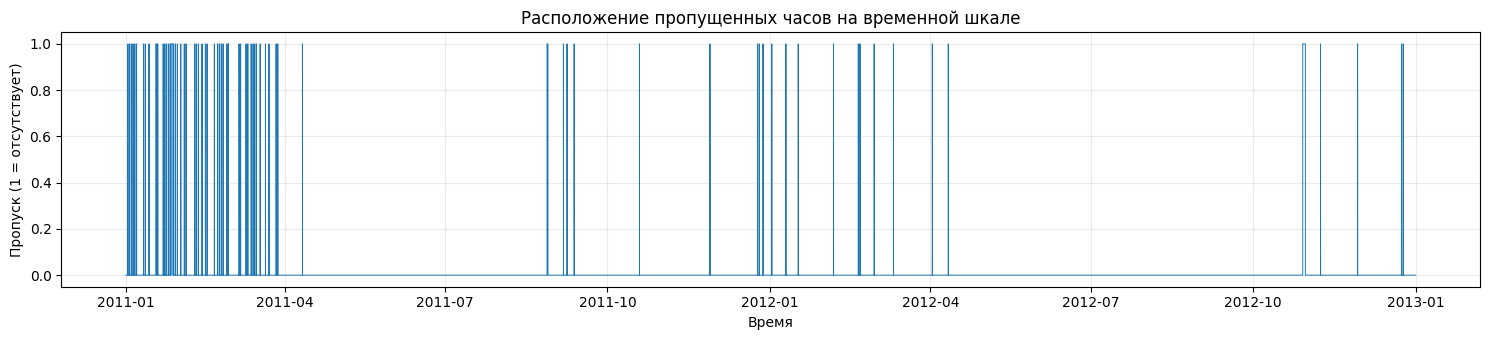

In [6]:
missing_mask = series.isna().to_numpy()
missing_count = int(missing_mask.sum())
missing_percent = 100 * missing_count / len(series) if len(series) else 0.0

missing_runs = []
run_start = None
for i, is_missing in enumerate(missing_mask):
    if is_missing and run_start is None:
        run_start = i
    if run_start is not None and (not is_missing or i == len(missing_mask) - 1):
        run_end = i if is_missing and i == len(missing_mask) - 1 else i - 1
        run_length = run_end - run_start + 1
        missing_runs.append({
            'Начало': series.index[run_start],
            'Конец': series.index[run_end],
            'Часов в последовательности': run_length,
        })
        run_start = None

runs_df = pd.DataFrame(missing_runs)
missing_summary = pd.DataFrame({
    'Показатель': [
        'Пропуски в целевой переменной исходного CSV',
        'Отсутствующие часовые метки (добавлены как NaN)',
        'NaN в аналитическом ряду после регуляризации',
        'Доля NaN в аналитическом ряду, %',
        'Непрерывные последовательности пропусков',
        'Максимальная последовательность, часов',
    ],
    'Значение': [
        source_missing_cnt,
        missing_timestamp_count,
        missing_count,
        round(missing_percent, 3),
        len(runs_df),
        int(runs_df['Часов в последовательности'].max()) if not runs_df.empty else 0,
    ]
})
display(missing_summary)
if not runs_df.empty:
    display(runs_df.head(20))
    runs_df.to_csv(OUTPUT_DIR / 'missing_runs.csv', index=False)

fig, ax = plt.subplots(figsize=(15, 3.5))
ax.plot(series.index, series.isna().astype(int), drawstyle='steps-post', linewidth=0.7)
ax.set_title('Расположение пропущенных часов на временной шкале')
ax.set_xlabel('Время')
ax.set_ylabel('Пропуск (1 = отсутствует)')
ax.grid(True, alpha=0.25)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / '05_missing_timestamps.png', dpi=150, bbox_inches='tight')
plt.show()

## 7. Сравнение четырёх методов импутации на искусственно скрытых значениях

Для объективного сравнения из исходно известных значений случайно скрывается 10% точек. Одни и те же контрольные позиции используются для всех методов. Сравниваются четыре способа, указанные в практике лекции:

1. **Forward fill (`ffill`)** — последнее известное значение переносится вперёд. Если пропуск стоит в самом начале ряда и предыдущего наблюдения нет, применяется обратное заполнение только для этой граничной ситуации.
2. **Линейная интерполяция** — значение восстанавливается по соседним известным точкам. Метод использует данные до и после пропуска.
3. **Медиана** — пропуск заменяется медианой всех доступных значений `cnt` после маскирования.
4. **Seasonal naive** — подставляется значение того же часа предыдущих суток (лаг 24 часа); при необходимости поиск продолжается до 14 суток назад.

Если seasonal naive не находит сезонный аналог, включается резервная линейная интерполяция, а на границах ряда — ближайшее доступное значение. Следовательно, для таких точек резервное восстановление может использовать значения из будущего. Это допустимо для ретроспективной импутации и оценки EDA, но не является причинно-ограниченным прогнозированием. Число точек, потребовавших резервного заполнения, выводится отдельно.

Качество всех методов сравнивается на одинаковом наборе искусственно скрытых точек по MAE и RMSE.

,Метод,Число тестовых точек,MAE,RMSE
0,Линейная интерполяция,1738,38.334,65.376
1,Seasonal naive (лаг 24 ч),1738,65.799,110.238
2,Forward fill (ffill),1738,69.992,109.437
3,Медиана,1738,139.535,190.671


,Метод,Дополнительное заполнение на границе,Пояснение
0,Forward fill (ffill),0,bfill применяется только если в начале ряда отсутствует предыдущее наблюдение.
1,Линейная интерполяция,0,На краях ряда используются ближайшие доступные значения.
2,Медиана,0,"Все пропуски заменяются одной медианой, рассчитанной по наблюдаемым значениям."
3,Seasonal naive,1,После 14 сезонных лагов остаточные NaN заполняются интерполяцией; на краях — ближайшими значениями.


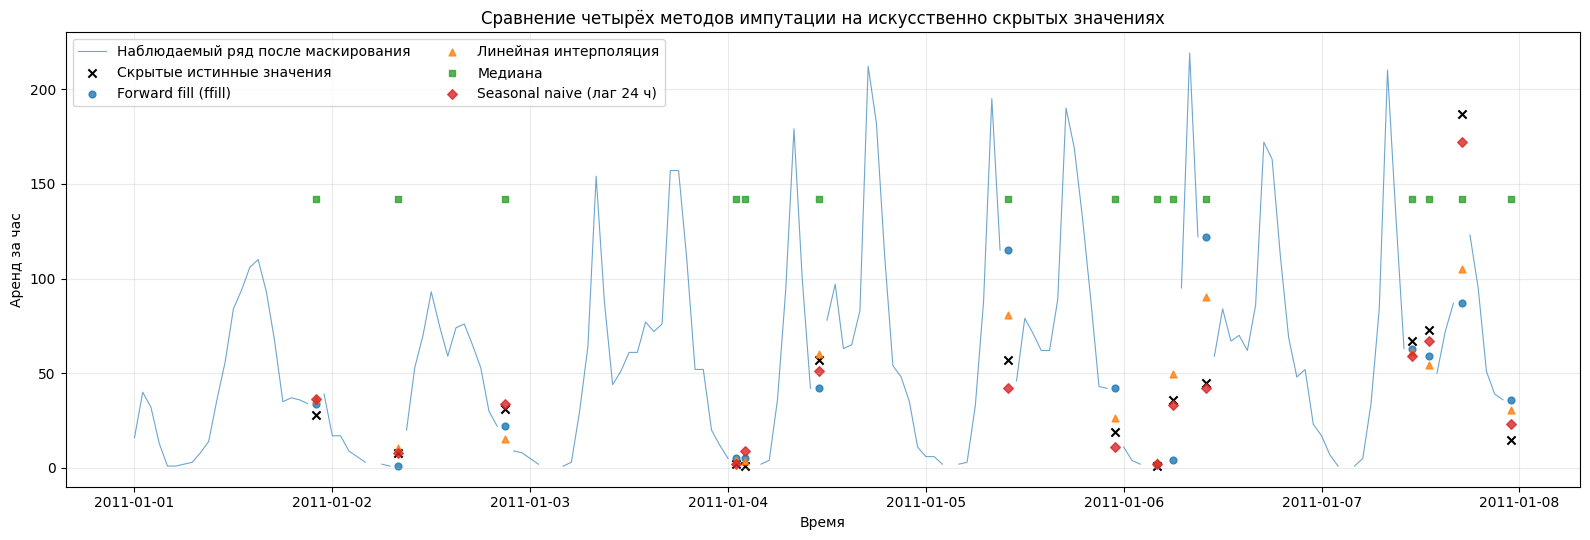

Наименьший MAE: Линейная интерполяция
Наименьший RMSE: Линейная интерполяция
Seasonal naive потребовал резервного заполнения для 1 ячеек ряда.


In [ ]:
# Маскируем только реально наблюдавшиеся значения, отсутствующие часы не входят в тестовую выборку.
valid_positions = np.flatnonzero(series.notna().to_numpy())
rng = np.random.default_rng(SEED)
holdout_count = max(1, int(round(0.10 * len(valid_positions))))
holdout_positions = np.sort(rng.choice(valid_positions, size=holdout_count, replace=False))
truth = series.copy()
masked_series = series.copy()
masked_series.iloc[holdout_positions] = np.nan

# 1. Forward fill. Для начального края, где нет предыдущего значения,
# используется bfill, число таких граничных точек фиксируется отдельно.
ffill_only = masked_series.ffill()
ffill_edge_fallback_count = int(ffill_only.isna().sum())
ffill_imputed = ffill_only.bfill()

# 2. Линейная интерполяция по временной оси, на границах — ближайшее наблюдение.
linear_interpolated = masked_series.interpolate(method='time')
linear_edge_fallback_count = int(linear_interpolated.isna().sum())
linear_imputed = linear_interpolated.ffill().bfill()

# 3. Глобальная медиана по доступным значениям после маскирования.
observed_median = float(masked_series.median())
median_imputed = masked_series.fillna(observed_median)

# 4. Seasonal naive: тот же час предыдущих суток, до 14 сезонных лагов назад.
def seasonal_naive_impute(values: pd.Series, period: int = 24, max_days: int = 14):
    """Возвращает (заполненный ряд, число NaN, оставшихся перед резервным методом)."""
    filled = values.copy()
    for _ in range(max_days):
        filled = filled.fillna(filled.shift(period))
    fallback_mask = filled.isna()
    fallback_count = int(fallback_mask.sum())
    # Резерв: time interpolation, затем bfill/ffill для краёв.
    filled = filled.interpolate(method='time').ffill().bfill()
    return filled, fallback_count

seasonal_imputed, seasonal_fallback_count = seasonal_naive_impute(masked_series, period=24, max_days=14)

imputed_series = {
    'Forward fill (ffill)': ffill_imputed,
    'Линейная интерполяция': linear_imputed,
    'Медиана': median_imputed,
    'Seasonal naive (лаг 24 ч)': seasonal_imputed,
}

actual_test = truth.iloc[holdout_positions].to_numpy(dtype=float)

def error_metrics(actual, predicted):
    errors = np.asarray(predicted, dtype=float) - np.asarray(actual, dtype=float)
    return float(np.mean(np.abs(errors))), float(np.sqrt(np.mean(errors ** 2)))

rows = []
for method_name, filled in imputed_series.items():
    prediction = filled.iloc[holdout_positions].to_numpy(dtype=float)
    mae, rmse = error_metrics(actual_test, prediction)
    rows.append({'Метод': method_name, 'Число тестовых точек': holdout_count, 'MAE': mae, 'RMSE': rmse})

imputation_results = pd.DataFrame(rows).sort_values(['MAE', 'RMSE']).reset_index(drop=True)
display(imputation_results.round(3))
imputation_results.to_csv(OUTPUT_DIR / 'imputation_comparison.csv', index=False)

fallback_summary = pd.DataFrame([
    {'Метод': 'Forward fill (ffill)', 'Дополнительное заполнение на границе': ffill_edge_fallback_count,
     'Пояснение': 'bfill применяется только если в начале ряда отсутствует предыдущее наблюдение.'},
    {'Метод': 'Линейная интерполяция', 'Дополнительное заполнение на границе': linear_edge_fallback_count,
     'Пояснение': 'На краях ряда используются ближайшие доступные значения.'},
    {'Метод': 'Медиана', 'Дополнительное заполнение на границе': 0,
     'Пояснение': 'Все пропуски заменяются одной медианой, рассчитанной по наблюдаемым значениям.'},
    {'Метод': 'Seasonal naive', 'Дополнительное заполнение на границе': seasonal_fallback_count,
     'Пояснение': 'После 14 сезонных лагов остаточные NaN заполняются интерполяцией; на краях — ближайшими значениями.'},
])
pd.set_option("display.max_colwidth", None)
display(fallback_summary)
fallback_summary.to_csv(OUTPUT_DIR / 'imputation_fallbacks.csv', index=False)

# Визуальное сравнение всех методов на семидневном фрагменте вокруг первой тестовой точки.
first_test_time = truth.index[holdout_positions[0]]
plot_start = first_test_time.floor('D')
plot_end = plot_start + pd.Timedelta(days=7)
region = (truth.index >= plot_start) & (truth.index < plot_end)
test_in_region = np.intersect1d(holdout_positions, np.flatnonzero(region))
fig, ax = plt.subplots(figsize=(16, 5.5))
ax.plot(truth.index[region], masked_series.iloc[np.flatnonzero(region)].values,
        linewidth=0.8, alpha=0.65, label='Наблюдаемый ряд после маскирования')
if len(test_in_region):
    ax.scatter(truth.index[test_in_region], truth.iloc[test_in_region], marker='x', s=35,
               color='black', label='Скрытые истинные значения')
    markers = ['o', '^', 's', 'D']
    for (method_name, filled), marker in zip(imputed_series.items(), markers):
        ax.scatter(truth.index[test_in_region], filled.iloc[test_in_region], marker=marker,
                   s=24, alpha=0.8, label=method_name)
ax.set_title('Сравнение четырёх методов импутации на искусственно скрытых значениях')
ax.set_xlabel('Время')
ax.set_ylabel('Аренд за час')
ax.legend(ncol=2)
ax.grid(True, alpha=0.25)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / '06_imputation_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

best_mae_method = imputation_results.loc[imputation_results['MAE'].idxmin(), 'Метод']
best_rmse_method = imputation_results.loc[imputation_results['RMSE'].idxmin(), 'Метод']
print(f'Наименьший MAE: {best_mae_method}')
print(f'Наименьший RMSE: {best_rmse_method}')
print(f'Seasonal naive потребовал резервного заполнения для {seasonal_fallback_count} ячеек ряда.')

## 8. Обнаружение выбросов: IQR, z-score и rolling median / MAD

Каждый метод применяется к исходным наблюдаемым значениям `cnt`, отсутствующие часы остаются пропусками. IQR и z-score выявляют глобальные отклонения, а rolling median / MAD оценивает отклонение относительно локального уровня. В реальном ряду высокие значения аренды могут отражать реальные пики спроса, поэтому пометка статистическим методом означает «кандидат на аномалию», а не автоматически ошибку данных.

,Метод,Порог,Число отмеченных точек
0,IQR,< -321.50 или > 642.50,505
1,z-score,|z-score| > 3,244
2,Rolling median / MAD,|robust z| > 3.5; окно {rolling_window} ч,29


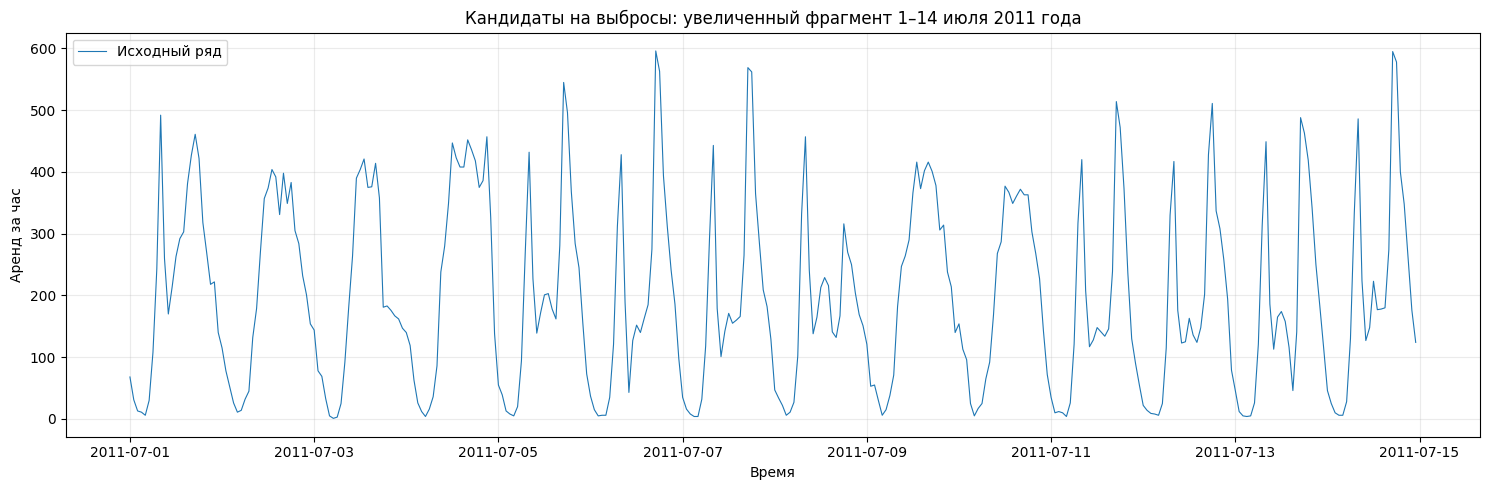

In [8]:
valid = series.dropna()
q1, q3 = valid.quantile([0.25, 0.75])
iqr = q3 - q1
iqr_lower, iqr_upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
iqr_flag = (series < iqr_lower) | (series > iqr_upper)

mean_value = valid.mean()
std_value = valid.std(ddof=0)
z_score = (series - mean_value) / std_value if std_value > 0 else series * 0
z_flag = z_score.abs() > 3.0

rolling_window = 169  # примерно одна неделя; нечётное окно для центрированной медианы
rolling_median = series.rolling(rolling_window, center=True, min_periods=72).median()
absolute_residual = (series - rolling_median).abs()
rolling_mad = absolute_residual.rolling(rolling_window, center=True, min_periods=72).median()
robust_z = 0.6745 * (series - rolling_median) / rolling_mad.replace(0, np.nan)
rolling_mad_flag = robust_z.abs() > 3.5

outlier_flags = pd.DataFrame({
    'IQR': iqr_flag.fillna(False),
    'z-score': z_flag.fillna(False),
    'Rolling median / MAD': rolling_mad_flag.fillna(False),
}, index=series.index)
outlier_results = pd.DataFrame({
    'Метод': ['IQR', 'z-score', 'Rolling median / MAD'],
    'Порог': [
        f'< {iqr_lower:.2f} или > {iqr_upper:.2f}',
        '|z-score| > 3',
        '|robust z| > 3.5; окно {rolling_window} ч',
    ],
    'Число отмеченных точек': [int(outlier_flags[c].sum()) for c in outlier_flags.columns],
})
display(outlier_results)
outlier_results.to_csv(OUTPUT_DIR / 'outlier_detection_comparison.csv', index=False)
outlier_flags.to_csv(OUTPUT_DIR / 'outlier_flags_by_timestamp.csv', index_label='timestamp')

plot_start = pd.Timestamp('2011-07-01')
plot_end = plot_start + pd.Timedelta(days=14)
region = (series.index >= plot_start) & (series.index < plot_end)
fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(series.index[region], series.iloc[np.flatnonzero(region)], linewidth=0.8, label='Исходный ряд')
for method, marker in [('IQR', 'o'), ('z-score', 'x'), ('Rolling median / MAD', '^')]:
    selected = region & outlier_flags[method].to_numpy()
    if selected.any():
        ax.scatter(series.index[selected], series[selected], s=28, marker=marker, label=method)
ax.set_title('Кандидаты на выбросы: увеличенный фрагмент 1–14 июля 2011 года')
ax.set_xlabel('Время')
ax.set_ylabel('Аренд за час')
ax.legend()
ax.grid(True, alpha=0.25)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / '07_outlier_detection.png', dpi=150, bbox_inches='tight')
plt.show()

## 9. Список проблем качества данных

Таблица ниже формируется из фактических результатов проверок. В ней разделены проблемы исходного CSV и особенности, которые обнаруживаются после приведения временного индекса к регулярной сетке. 

In [11]:
max_missing_run = int(runs_df['Часов в последовательности'].max()) if not runs_df.empty else 0
quality_issues = pd.DataFrame([
    {
        'Проблема качества данных': 'Отсутствующие часовые метки',
        'Количество': missing_timestamp_count,
        'Оценка / последствие': 'После регуляризации отсутствующие часы представлены как NaN, импутация нужна только для методов, которым требуется непрерывный ряд.' if missing_timestamp_count else 'На регулярной сетке пропущенных временных меток не обнаружено.'
    },
    {
        'Проблема качества данных': 'Пропуски cnt в существующих строках исходного CSV',
        'Количество': source_missing_cnt,
        'Оценка / последствие': 'Отсутствующие значения целевого показателя непосредственно влияют на анализ спроса и должны быть отделены от отсутствующих временных меток.' if source_missing_cnt else 'В исходных строках CSV пропусков целевой переменной cnt не обнаружено.'
    },
    {
        'Проблема качества данных': 'Пустые ячейки во всех столбцах исходного CSV (включая cnt)',
        'Количество': source_missing_cells,
        'Оценка / последствие': 'Суммарный показатель по всем полям; не складывать с отдельной строкой по cnt.' if source_missing_cells else 'Пустых ячеек в исходной таблице не обнаружено.'
    },
    {
        'Проблема качества данных': 'Дубликаты временных меток',
        'Количество': duplicate_timestamp_count,
        'Оценка / последствие': 'Дубликаты удалялись после сортировки; проверить правило выбора записи, если они найдены.' if duplicate_timestamp_count else 'Дубликатов временных меток не обнаружено.'
    },
    {
        'Проблема качества данных': 'Некорректные временные метки',
        'Количество': invalid_timestamp_rows,
        'Оценка / последствие': 'Такие строки невозможно корректно расположить на временной шкале.' if invalid_timestamp_rows else 'Некорректных временных меток не обнаружено.'
    },
    {
        'Проблема качества данных': 'Отрицательные значения cnt',
        'Количество': negative_cnt_rows,
        'Оценка / последствие': 'Отрицательное число аренд физически неинтерпретируемо.' if negative_cnt_rows else 'Отрицательных значений целевого показателя не обнаружено.'
    },
    {
        'Проблема качества данных': 'Кандидаты на выбросы по IQR',
        'Количество': int(outlier_flags['IQR'].sum()),
        'Оценка / последствие': 'Нужна проверка: экстремальный спрос может быть реальным событием, а не ошибкой.'
    },
    {
        'Проблема качества данных': 'Кандидаты на выбросы по z-score',
        'Количество': int(outlier_flags['z-score'].sum()),
        'Оценка / последствие': 'Глобальный критерий может отмечать регулярные пики из-за суточного цикла.'
    },
    {
        'Проблема качества данных': 'Кандидаты на выбросы по rolling median / MAD',
        'Количество': int(outlier_flags['Rolling median / MAD'].sum()),
        'Оценка / последствие': 'Локальный критерий чувствителен к изменению уровня спроса и коротким всплескам.'
    },
    {
        'Проблема качества данных': 'Искусственно скрытые значения в эксперименте импутации',
        'Количество': holdout_count,
        'Оценка / последствие': 'Созданы специально для объективного сравнения методов - это не пропуски исходного датасета.'
    },
])
pd.set_option("display.max_colwidth", None)
display(quality_issues)
quality_issues.to_csv(OUTPUT_DIR / 'quality_issues.csv', index=False)

,Проблема качества данных,Количество,Оценка / последствие
0,Отсутствующие часовые метки,165,"После регуляризации отсутствующие часы представлены как NaN, импутация нужна только для методов, которым требуется непрерывный ряд."
1,Пропуски cnt в существующих строках исходного CSV,0,В исходных строках CSV пропусков целевой переменной cnt не обнаружено.
2,Пустые ячейки во всех столбцах исходного CSV (включая cnt),0,Пустых ячеек в исходной таблице не обнаружено.
3,Дубликаты временных меток,0,Дубликатов временных меток не обнаружено.
4,Некорректные временные метки,0,Некорректных временных меток не обнаружено.
5,Отрицательные значения cnt,0,Отрицательных значений целевого показателя не обнаружено.
6,Кандидаты на выбросы по IQR,505,"Нужна проверка: экстремальный спрос может быть реальным событием, а не ошибкой."
7,Кандидаты на выбросы по z-score,244,Глобальный критерий может отмечать регулярные пики из-за суточного цикла.
8,Кандидаты на выбросы по rolling median / MAD,29,Локальный критерий чувствителен к изменению уровня спроса и коротким всплескам.
9,Искусственно скрытые значения в эксперименте импутации,1738,Созданы специально для объективного сравнения методов - это не пропуски исходного датасета.


## 10. Краткие выводы

1. Использован открытый почасовой Bike Sharing Dataset: 17379 уникальных записей за период с 01.01.2011 00:00 по 31.12.2012 23:00. Источник: UCI Machine Learning Repository.

2. Временной профиль демонстрирует суточную и недельную сезонность: максимум среднего числа аренд приходится на 17:00, минимум — на 4:00. По дням недели максимум наблюдается в день «Чт», минимум — в день «Вс».

3. Среднее значение cnt в 2012 г. увеличилось относительно 2011 г. на 63.20%. В 12 из 12 сопоставимых календарных месяцев среднее 2012 г. было выше, чем в 2011 г. Это описательное свидетельство изменения уровня, но не формальное доказательство структурного разрыва. Результат следует трактовать с учётом сезонности и неполного покрытия отдельных часов.

4. На 1738 одинаковых для всех методов искусственно скрытых значениях сравнивались ffill, линейная интерполяция, медиана и seasonal naive. Наименьший MAE показал метод «Линейная интерполяция», наименьший RMSE — «Линейная интерполяция».

5. Пропуски исходного ряда включают 0 пустых значений cnt в строках CSV и 165 отсутствующих часовых меток после регуляризации. Отсутствующий час не обязательно означает ошибку измерения: возможны часы с нулевым спросом/отсутствием аренд, поэтому такие точки не заменялись нулями без подтверждения семантики источника.

6. Методы IQR, z-score и rolling median / MAD отметили соответственно 505, 244 и 29 кандидатов на выбросы. Они требуют контекстной проверки и не являются автоматически ошибками.

7. Seasonal naive потребовал резервного заполнения для 1 ячеек ряда после исчерпания сезонных лагов. В этих случаях интерполяция может использовать будущие значения, поэтому результат относится к ретроспективной импутации, а не к прогнозу в реальном времени.

## 11. Ссылки на данные

Fanaee-T, H. (2013). *Bike Sharing Dataset*. UCI Machine Learning Repository. https://doi.org/10.24432/C5W894.

Официальная страница с описанием признаков и файлами: https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset

CSV-зеркало, используемое в ноутбуке: https://raw.githubusercontent.com/udacity/deep-learning/master/first-neural-network/Bike-Sharing-Dataset/hour.csv